# Week 7 Tugas Kelompok: Perbandingan OCR pada KTP



## 1. Instal Tesseract dan bahasa Indonesia, lalu hubungkan Drive


In [1]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pytesseract
from pytesseract import Output
from IPython.display import display

FOLDER = '/content/drive/MyDrive/PCVK/'
FILES = {'Saya': 'ktp_saya.jpeg', 'Teman': 'ktp_teman.jpeg'}
METODE = ['Berwarna asli', 'Segmentasi Otsu', 'Segmentasi Adaptive']
BAHASA = 'ind'
CONFIG = '--psm 6'
BATAS_CONFIDENCE = 60

print('Tesseract:', pytesseract.get_tesseract_version())
if BAHASA not in pytesseract.get_languages(config=''):
    raise RuntimeError('Bahasa Indonesia belum tersedia. Jalankan sel instalasi.')


Tesseract: 5.3.4


## 2. Siapkan tiga citra untuk setiap anggota

Otsu memakai cv.threshold() dan Adaptive memakai cv.adaptiveThreshold(),
sesuai contoh modul. Adaptive Gaussian menggunakan jendela **11×11** dan
**C=2**. Kedua threshold diterapkan setelah konversi grayscale.
Tidak ada resize atau crop: ketiga citra dari satu KTP memiliki ukuran sama.
Citra warna diubah dari BGR ke RGB untuk tampilan dan Tesseract.

Saya: ukuran (645, 1024), threshold Otsu = 127


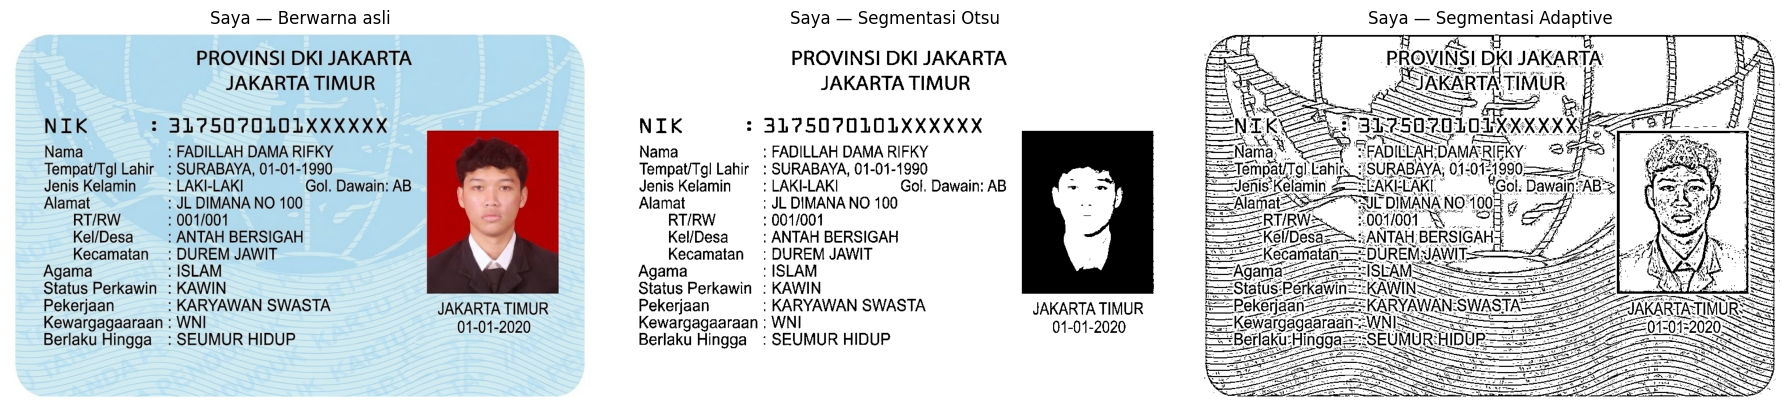

Teman: ukuran (676, 1024), threshold Otsu = 127


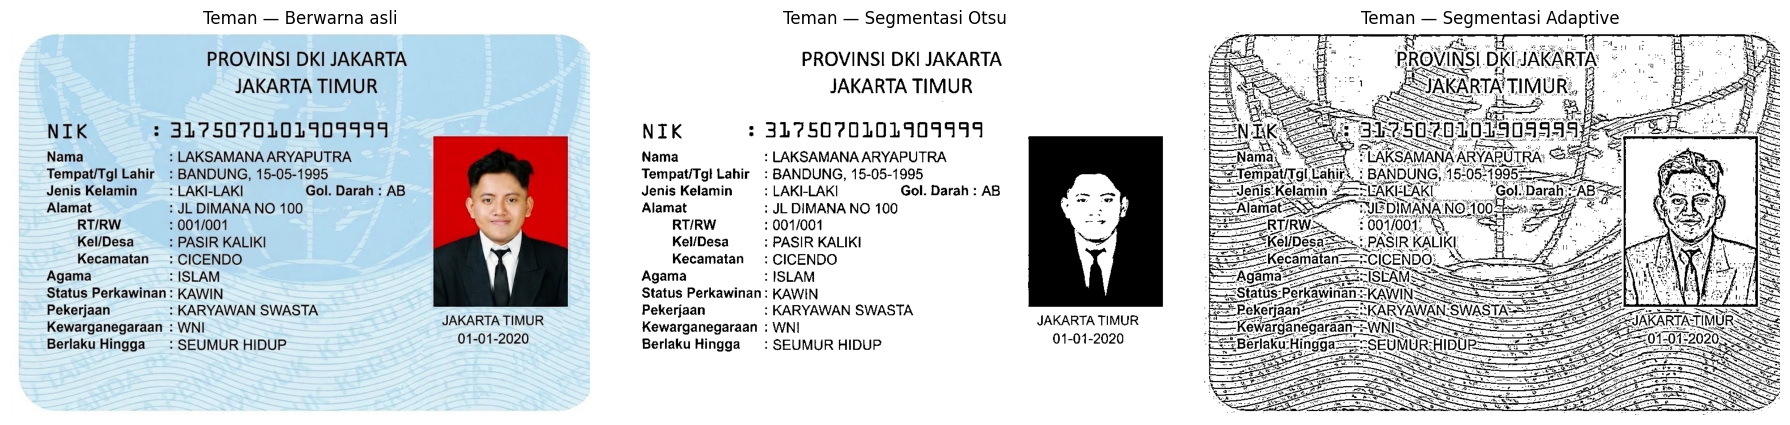

In [4]:
citra_anggota = {}

for anggota, filename in FILES.items():
    bgr = cv.imread(FOLDER + filename)
    if bgr is None:
        raise FileNotFoundError('Gambar tidak dapat dibaca: ' + FOLDER + filename)
    rgb = cv.cvtColor(bgr, cv.COLOR_BGR2RGB)
    gray = cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)
    T, otsu = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    adaptive = cv.adaptiveThreshold(
        gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2
    )
    citra_anggota[anggota] = [rgb, otsu, adaptive]
    print(f'{anggota}: ukuran {gray.shape}, threshold Otsu = {T:.0f}')
    plt.figure(figsize=(18, 6))
    for i, (citra, metode) in enumerate(zip(citra_anggota[anggota], METODE)):
        plt.subplot(1, 3, i + 1)
        if citra.ndim == 2:
            plt.imshow(citra, cmap='gray', vmin=0, vmax=255)
        else:
            plt.imshow(citra)
        plt.title(f'{anggota} — {metode}')
        plt.axis('off')
    plt.tight_layout()
    plt.show()


## 3. Baca teks dan tampilkan kotak hijau

image_to_string() menghasilkan teks lengkap. image_to_data() memberikan
posisi dan confidence kata. Semua metode memakai bahasa **ind**, **--psm 6**,
dan kotak hijau untuk confidence **> 60**.
Penilaian kecocokan memakai **seluruh teks OCR**, termasuk kata tanpa kotak.

Rata-rata confidence dihitung dari semua kata tidak kosong dengan confidence
**≥ 0**, bukan hanya kata berkotak. Nilai -1 menandai elemen struktur halaman
dan tidak ikut dihitung. Aturan ini sama untuk ketiga metode.
Jika tidak ada kata terbaca, rata-rata confidence ditampilkan NaN.

In [ ]:
def baca_ocr(citra):
    teks = pytesseract.image_to_string(citra, lang=BAHASA, config=CONFIG)
    data_ocr = pytesseract.image_to_data(
        citra, lang=BAHASA, config=CONFIG, output_type=Output.DICT
    )
    gambar_kotak = citra.copy()
    if citra.ndim == 2:
        gambar_kotak = cv.cvtColor(citra, cv.COLOR_GRAY2RGB)
    confidence_kata = []
    for i in range(len(data_ocr['text'])):
        kata = data_ocr['text'][i].strip()
        confidence = float(data_ocr['conf'][i])
        if kata and confidence >= 0:
            confidence_kata.append(confidence)
        if kata and confidence > BATAS_CONFIDENCE:
            x, y = data_ocr['left'][i], data_ocr['top'][i]
            w, h = data_ocr['width'][i], data_ocr['height'][i]
            cv.rectangle(gambar_kotak, (x, y), (x + w, y + h), (0, 255, 0), 2)
    rata_confidence = float(np.mean(confidence_kata)) if confidence_kata else np.nan
    return teks, gambar_kotak, rata_confidence



--- Saya: Berwarna asli ---
PROVINSI DKI JAKARTA
JAKARTA TIMUR
NIK 1 31?5070ULOLXXXXXX
Nama : FADILLAH DAMA RIFKY
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin : LAKI-LAKI Gol. Dawain: AB | -
Alamat : JL DIMANA NO 100 | Sg
RT/RW : 001/001 .
Kel/Desa : ANTAH BERSIGAH
Kecamatan : DUREM JAWIT
Agama "ISLAM
Status Perkawin : KAWIN
Pekerjaan : KARYAWAN SWASTA JAKARTA TIMUR
Kewargagaaraan : WNI 01-01-2020
Berlaku Hingga : SEUMUR HIDUP

Rata-rata confidence: 84.90

--- Saya: Segmentasi Otsu ---
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 3195070LOLXXXXXX
Nama : FADILLAH DAMA RIFKY
Tempat/Tgl Lahir : SURABAYA, 01-01-1990 .
Jenis Kelamin : LAKI-LAKI Gol. Dawain: AB
Alamat : JL DIMANA NO 100 ||

RT/RW : 001/001

Kel/Desa : ANTAH BERSIGAH

Kecamatan : DUREM JAWIT
Agama "ISLAM
Status Perkawin : KAWIN
Pekerjaan : KARYAWAN SWASTA JAKARTA TIMUR
Kewargagaaraan : WNI 01-01-2020
Berlaku Hingga : SEUMUR HIDUP

Rata-rata confidence: 83.58

--- Saya: Segmentasi Adaptive ---
TG H Tr XI os F Ex
Ea : PR

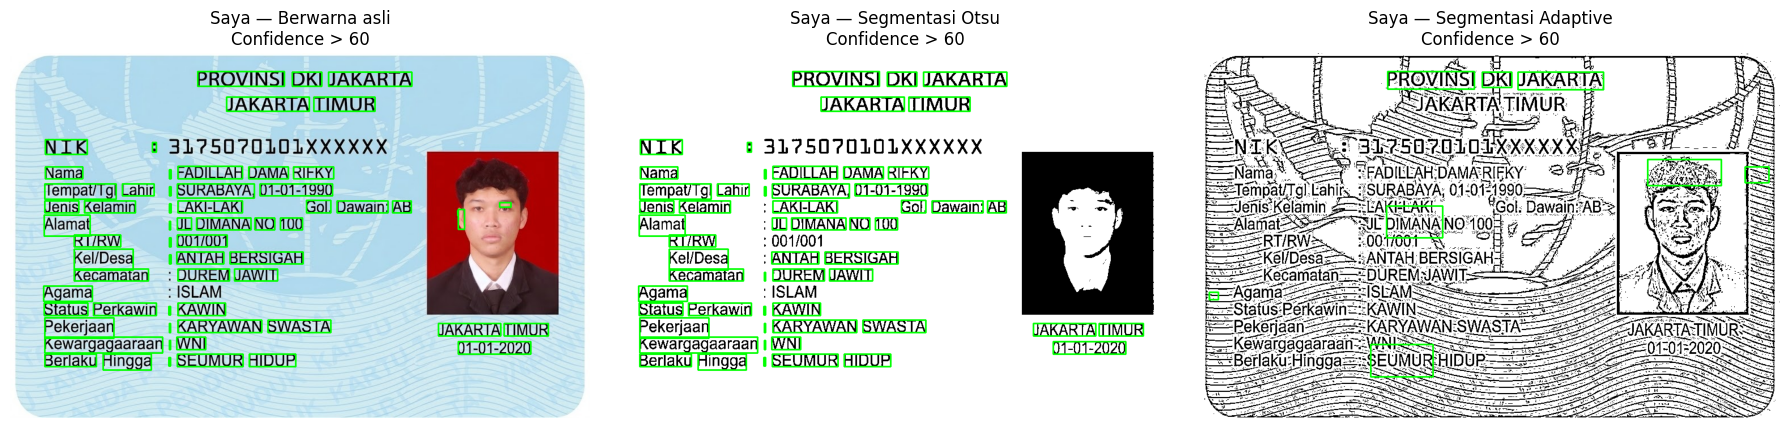


--- Teman: Berwarna asli ---
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 3175070101409444
Nama : LAKSAMANA ARYAPUTRA
Tempat/Tgl Lahir : BANDUNG, 15-05-1995
Jenis Kelamin : LAKI-LAKI Gol. Darah : AB — A
Alamat : JL DIMANA NO 100 GAN

RT/RW : 001/001

Kel/Desa : PASIR KALIKI

Kecamatan ..: CICENDO
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI CaKARTAs UMR
Berlaku Hingga: SEUMUR HIDUP DU

Rata-rata confidence: 81.20

--- Teman: Segmentasi Otsu ---
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 317 50?70101409949
Nama : LAKSAMANA ARYAPUTRA
Tempat/Tgl Lahir : BANDUNG, 15-05-1995
Jenis Kelamin 1 LAKI-LAKI Gol. Darah : A8
Alamat : JL DIMANA NO 100 |

RT/RW : 001/001

Kel/Desa : PASIR KALIKI

Kecamatan : CICENDO
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

Rata-rata confidence: 85.18

--- Teman: Segmentasi Adaptive ---
Pj pro Yg F1 T - : pn F an
SE ae SPL

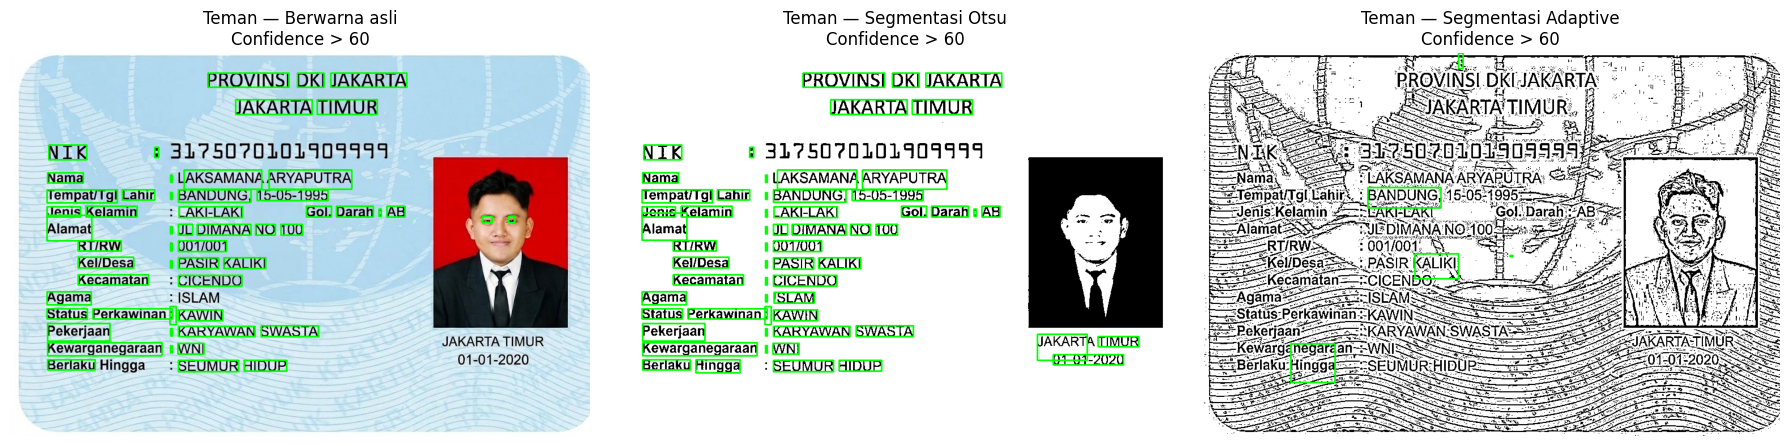

In [6]:
hasil_ocr = {}

for anggota, daftar_citra in citra_anggota.items():
    hasil_ocr[anggota] = {}
    plt.figure(figsize=(18, 6))
    for i, (citra, metode) in enumerate(zip(daftar_citra, METODE)):
        teks, gambar_kotak, rata_confidence = baca_ocr(citra)
        hasil_ocr[anggota][metode] = {
            'teks': teks,
            'confidence': rata_confidence,
        }
        print(f'\n--- {anggota}: {metode} ---')
        print(teks if teks.strip() else '(Tidak ada teks yang terbaca)')
        print(f'Rata-rata confidence: {rata_confidence:.2f}')
        plt.subplot(1, 3, i + 1)
        plt.imshow(gambar_kotak)
        plt.title(f'{anggota} — {metode}\nConfidence > {BATAS_CONFIDENCE}')
        plt.axis('off')
    plt.tight_layout()
    plt.show()


## 4. Ringkasan confidence awal

Confidence adalah keyakinan Tesseract, bukan persentase kecocokan dengan
tulisan sebenarnya. Kecocokan dihitung terpisah dari 10 acuan.

In [ ]:
baris_confidence = []
for anggota in FILES:
    for metode in METODE:
        baris_confidence.append({
            'Anggota': anggota,
            'Citra masukan OCR': metode,
            'Rata-rata confidence': hasil_ocr[anggota][metode]['confidence'],
        })
display(pd.DataFrame(baris_confidence).round(2))


,Anggota,Citra masukan OCR,Rata-rata confidence
0,Saya,Berwarna asli,84.90
1,Saya,Segmentasi Otsu,83.58
2,Saya,Segmentasi Adaptive,23.42
3,Teman,Berwarna asli,81.20
4,Teman,Segmentasi Otsu,85.18
5,Teman,Segmentasi Adaptive,20.76


## 5. Sepuluh acuan untuk setiap KTP

Acuan berikut telah dipilih dari gambar asli pada output bagian 2.
Setiap baris berisi **teks sebenarnya, OCR berwarna, OCR Otsu, dan OCR Adaptive**.
Bacaan disalin dari seluruh teks OCR pada bagian 3, termasuk kata tanpa kotak.
Jika item tidak terbaca, kolom OCR kosong. Salah eja dan tanda baca OCR
dipertahankan. Bila kata menyatu dengan kata/label lain, token hasil OCR
yang memuat item tersebut dipertahankan dan dinilai tidak cocok.

Acuan mengikuti tulisan pada gambar, termasuk ejaan DUREM dan BERSIGAH
yang memang terlihat pada KTP Saya. Jalankan sel ini dan bagian 6–7
untuk menghitung ulang hasilnya dalam sesi Colab.


In [8]:
# Acuan dibaca dari citra asli yang tersimpan pada output bagian 2.
# Bacaan OCR disalin dari output bagian 3, tanpa koreksi salah eja.
# Urutan: acuan, OCR berwarna, OCR Otsu, OCR Adaptive.
penilaian = {
    'Saya': [
        ['JAKARTA', 'JAKARTA', 'JAKARTA', 'JAKARTA'],  # 1
        ['FADILLAH', 'FADILLAH', 'FADILLAH', 'TEADILAHDAMAREKY'],  # 2
        ['01-01-1990', '01-01-1990', '01-01-1990', '01:0121990—'],  # 3
        ['LAKI-LAKI', 'LAKI-LAKI', 'LAKI-LAKI', 'ASLAKELAKI”——'],  # 4
        ['001/001', '001/001', '001/001', '1001/7001.'],  # 5
        ['ANTAH', 'ANTAH', 'ANTAH', 'ANTAH'],  # 6
        ['BERSIGAH', 'BERSIGAH', 'BERSIGAH', 'BERSIGAH'],  # 7
        ['DUREM', 'DUREM', 'DUREM', ''],  # 8
        ['WNI', 'WNI', 'WNI', 'WN'],  # 9
        ['SEUMUR', 'SEUMUR', 'SEUMUR', 'SEUMUR'],  # 10
    ],
    'Teman': [
        ['LAKSAMANA', 'LAKSAMANA', 'LAKSAMANA', 'MLAKSAMANAARYAPUTA'],  # 1
        ['15-05-1995', '15-05-1995', '15-05-1995', '15:05:1905z-—.'],  # 2
        ['LAKI-LAKI', 'LAKI-LAKI', 'LAKI-LAKI', 'A—5LAKILAKI'],  # 3
        ['AB', 'AB', 'A8', '“GekDaahsAb'],  # 4
        ['001/001', '001/001', '001/001', '1001001,'],  # 5
        ['PASIR', 'PASIR', 'PASIR', 'PASIR'],  # 6
        ['KALIKI', 'KALIKI', 'KALIKI', 'KALIKI,'],  # 7
        ['CICENDO', 'CICENDO', 'CICENDO', 'SCICENDOL'],  # 8
        ['ISLAM', 'ISLAM', 'ISLAM', 'ISLAM'],  # 9
        ['KAWIN', 'KAWIN', 'KAWIN', 'KAVINS'],  # 10
    ],
}


## 6. Tabel pembacaan dan persentase kecocokan

Item cocok jika seluruh huruf/angka sama. Hanya perbedaan huruf besar/kecil
dan spasi di awal/akhir yang diabaikan. Salah huruf, salah angka, tanda baca
berbeda, spasi di tengah berbeda, dan item tidak terbaca dinilai **tidak cocok**.

**Kecocokan (%) = jumlah item cocok / 10 × 100**.
Tabel yang belum memiliki 10 acuan tidak diberi nilai.

In [9]:
def normalisasi(teks):
    return teks.strip().lower()

def hitung_kecocokan(tabel, kolom_ocr):
    if len(tabel) != 10 or any(len(baris) != 4 for baris in tabel):
        raise ValueError('Tabel harus berisi 10 baris, masing-masing 4 kolom.')
    if any(not normalisasi(baris[0]) for baris in tabel):
        raise ValueError('Sepuluh teks acuan harus diisi terlebih dahulu.')
    return [normalisasi(baris[0]) == normalisasi(baris[kolom_ocr])
            for baris in tabel]

ringkasan_anggota = {}
status_kecocokan = {}

for anggota, tabel in penilaian.items():
    print(f'Tabel penilaian KTP: {anggota}')
    if len(tabel) != 10 or any(len(baris) != 4 for baris in tabel):
        raise ValueError(f'Tabel {anggota} harus berisi 10 baris dan 4 kolom.')
    if any(not normalisasi(baris[0]) for baris in tabel):
        print('Isi seluruh 10 acuan di bagian 5, lalu jalankan ulang bagian 6–7.')
        continue
    tabel_ocr = pd.DataFrame(tabel, columns=[
        'Teks sebenarnya', 'OCR citra berwarna', 'OCR Otsu', 'OCR Adaptive'
    ])
    tabel_ocr.index = range(1, 11)
    tabel_ocr.index.name = 'No.'
    display(tabel_ocr)
    ringkasan = []
    status_kecocokan[anggota] = {}
    for kolom, metode in enumerate(METODE, start=1):
        cocok = hitung_kecocokan(tabel, kolom)
        status_kecocokan[anggota][metode] = cocok
        ringkasan.append({
            'Citra masukan OCR': metode,
            'Item terbaca tepat': sum(cocok),
            'Kecocokan (%)': sum(cocok) / 10 * 100,
            'Rata-rata confidence': hasil_ocr[anggota][metode]['confidence'],
        })
    ringkasan_anggota[anggota] = pd.DataFrame(ringkasan)
    display(ringkasan_anggota[anggota].round(2))


Tabel penilaian KTP: Saya


,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
No.,,,,
1,JAKARTA,JAKARTA,JAKARTA,JAKARTA
2,FADILLAH,FADILLAH,FADILLAH,TEADILAHDAMAREKY
3,01-01-1990,01-01-1990,01-01-1990,01:0121990—
4,LAKI-LAKI,LAKI-LAKI,LAKI-LAKI,ASLAKELAKI”——
5,001/001,001/001,001/001,1001/7001.
6,ANTAH,ANTAH,ANTAH,ANTAH
7,BERSIGAH,BERSIGAH,BERSIGAH,BERSIGAH
8,DUREM,DUREM,DUREM,
9,WNI,WNI,WNI,WN


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,10,100.0,84.90
1,Segmentasi Otsu,10,100.0,83.58
2,Segmentasi Adaptive,4,40.0,23.42


Tabel penilaian KTP: Teman


,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
No.,,,,
1,LAKSAMANA,LAKSAMANA,LAKSAMANA,MLAKSAMANAARYAPUTA
2,15-05-1995,15-05-1995,15-05-1995,15:05:1905z-—.
3,LAKI-LAKI,LAKI-LAKI,LAKI-LAKI,A—5LAKILAKI
4,AB,AB,A8,“GekDaahsAb
5,001/001,001/001,001/001,"1001001,"
6,PASIR,PASIR,PASIR,PASIR
7,KALIKI,KALIKI,KALIKI,"KALIKI,"
8,CICENDO,CICENDO,CICENDO,SCICENDOL
9,ISLAM,ISLAM,ISLAM,ISLAM


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,10,100.0,81.20
1,Segmentasi Otsu,9,90.0,85.18
2,Segmentasi Adaptive,2,20.0,20.76


## 7. Jawaban pertanyaan analisis


In [10]:
for anggota, ringkasan in ringkasan_anggota.items():
    print(f'\n===== ANALISIS KTP {anggota.upper()} =====')
    nilai_terbaik = ringkasan['Kecocokan (%)'].max()
    terbaik = ringkasan.loc[
        ringkasan['Kecocokan (%)'] == nilai_terbaik, 'Citra masukan OCR'
    ].tolist()
    print(f'1. Metode paling tepat: {", ".join(terbaik)}; '
          f'{nilai_terbaik:.0f}% ({nilai_terbaik / 10:.0f} dari 10 item).')

    print('2. Contoh kesalahan pembacaan:')
    kesalahan = []
    for kolom, metode in enumerate(METODE, start=1):
        for i, cocok in enumerate(status_kecocokan[anggota][metode]):
            if not cocok:
                acuan = penilaian[anggota][i][0]
                terbaca = penilaian[anggota][i][kolom]
                kesalahan.append((metode, acuan, terbaca))
    for metode, acuan, terbaca in kesalahan[:2]:
        hasil = repr(terbaca) if terbaca.strip() else 'tidak terbaca'
        print(f'   {metode}: acuan {acuan!r}, hasil OCR {hasil}.')
    if len(kesalahan) < 2:
        print('   Kurang dari dua kesalahan pada 10 acuan ini; '
              'laporkan hasil sebenarnya, jangan membuat kesalahan fiktif.')

    nilai = dict(zip(ringkasan['Citra masukan OCR'], ringkasan['Kecocokan (%)']))
    print('3. Segmentasi tidak selalu meningkatkan ketepatan OCR.')
    for metode in METODE[1:]:
        perubahan = nilai[metode] - nilai[METODE[0]]
        hubungan = 'lebih tinggi' if perubahan > 0 else 'lebih rendah' if perubahan < 0 else 'sama'
        print(f'   {metode}: {nilai[metode]:.0f}%, {hubungan} dibanding '
              f'berwarna asli ({nilai[METODE[0]]:.0f}%).')

    print('4. Warna dan pola latar dapat menyerupai goresan huruf atau '
          'mengurangi kontras tulisan. Threshold dapat memisahkan teks '
          'dari latar, tetapi juga dapat menghilangkan goresan tipis atau '
          'mempertahankan pola latar sebagai noise. '
          'Periksa efeknya pada tiga citra di bagian 2–3.')

    confidence_valid = ringkasan.dropna(subset=['Rata-rata confidence'])
    if confidence_valid.empty:
        print('5. Tidak ada confidence kata yang valid untuk dibandingkan.')
    else:
        confidence_max = confidence_valid['Rata-rata confidence'].max()
        metode_conf = confidence_valid.loc[
            confidence_valid['Rata-rata confidence'] == confidence_max,
            'Citra masukan OCR'
        ].tolist()
        print(f'5. Confidence tertinggi: {", ".join(metode_conf)} '
              f'({confidence_max:.2f}).')
        for metode in metode_conf:
            jawaban = 'juga' if metode in terbaik else 'tidak'
            print(f'   {metode} {jawaban} memiliki kecocokan tertinggi '
                  f'({nilai[metode]:.0f}%).')
        print('   Confidence adalah keyakinan mesin; ketepatan harus '
              'dibuktikan dengan kecocokan terhadap acuan.')

if not ringkasan_anggota:
    print('Analisis tersedia setelah tabel 10 acuan pada bagian 5 diisi.')



===== ANALISIS KTP SAYA =====
1. Metode paling tepat: Berwarna asli, Segmentasi Otsu; 100% (10 dari 10 item).
2. Contoh kesalahan pembacaan:
   Segmentasi Adaptive: acuan 'FADILLAH', hasil OCR 'TEADILAHDAMAREKY'.
   Segmentasi Adaptive: acuan '01-01-1990', hasil OCR '01:0121990—'.
3. Segmentasi tidak selalu meningkatkan ketepatan OCR.
   Segmentasi Otsu: 100%, sama dibanding berwarna asli (100%).
   Segmentasi Adaptive: 40%, lebih rendah dibanding berwarna asli (100%).
4. Warna dan pola latar dapat menyerupai goresan huruf atau mengurangi kontras tulisan. Threshold dapat memisahkan teks dari latar, tetapi juga dapat menghilangkan goresan tipis atau mempertahankan pola latar sebagai noise. Periksa efeknya pada tiga citra di bagian 2–3.
5. Confidence tertinggi: Berwarna asli (84.90).
   Berwarna asli juga memiliki kecocokan tertinggi (100%).
   Confidence adalah keyakinan mesin; ketepatan harus dibuktikan dengan kecocokan terhadap acuan.

===== ANALISIS KTP TEMAN =====
1. Metode paling 

## 8. Hasil penilaian dan analisis dari output tersimpan


### KTP Saya Tabel pembacaan

| No. | Teks sebenarnya | OCR berwarna | OCR Otsu | OCR Adaptive |
|---|---|---|---|---|
| 1 | JAKARTA | JAKARTA | JAKARTA | JAKARTA |
| 2 | FADILLAH | FADILLAH | FADILLAH | TEADILAHDAMAREKY |
| 3 | 01-01-1990 | 01-01-1990 | 01-01-1990 | 01:0121990— |
| 4 | LAKI-LAKI | LAKI-LAKI | LAKI-LAKI | ASLAKELAKI”—— |
| 5 | 001/001 | 001/001 | 001/001 | 1001/7001. |
| 6 | ANTAH | ANTAH | ANTAH | ANTAH |
| 7 | BERSIGAH | BERSIGAH | BERSIGAH | BERSIGAH |
| 8 | DUREM | DUREM | DUREM | (tidak terbaca) |
| 9 | WNI | WNI | WNI | WN |
| 10 | SEUMUR | SEUMUR | SEUMUR | SEUMUR |

### KTP Saya Ringkasan

| Citra masukan OCR | Item terbaca tepat | Kecocokan (%) | Rata-rata confidence |
|---|---:|---:|---:|
| Berwarna asli | 10/10 | 100 | 84.90 |
| Segmentasi Otsu | 10/10 | 100 | 83.58 |
| Segmentasi Adaptive | 4/10 | 40 | 23.42 |

### KTP Teman Tabel pembacaan

| No. | Teks sebenarnya | OCR berwarna | OCR Otsu | OCR Adaptive |
|---|---|---|---|---|
| 1 | LAKSAMANA | LAKSAMANA | LAKSAMANA | MLAKSAMANAARYAPUTA |
| 2 | 15-05-1995 | 15-05-1995 | 15-05-1995 | 15:05:1905z-—. |
| 3 | LAKI-LAKI | LAKI-LAKI | LAKI-LAKI | A—5LAKILAKI |
| 4 | AB | AB | A8 | “GekDaahsAb |
| 5 | 001/001 | 001/001 | 001/001 | 1001001, |
| 6 | PASIR | PASIR | PASIR | PASIR |
| 7 | KALIKI | KALIKI | KALIKI | KALIKI, |
| 8 | CICENDO | CICENDO | CICENDO | SCICENDOL |
| 9 | ISLAM | ISLAM | ISLAM | ISLAM |
| 10 | KAWIN | KAWIN | KAWIN | KAVINS |

### KTP Teman Ringkasan

| Citra masukan OCR | Item terbaca tepat | Kecocokan (%) | Rata-rata confidence |
|---|---:|---:|---:|
| Berwarna asli | 10/10 | 100 | 81.20 |
| Segmentasi Otsu | 9/10 | 90 | 85.18 |
| Segmentasi Adaptive | 2/10 | 20 | 20.76 |

### Jawaban analisis KTP Saya

1. **Berwarna asli dan Otsu sama-sama paling tepat**, masing-masing 10/10
   atau 100%. Adaptive hanya 4/10 atau 40% pada acuan yang dipilih.
2. Contoh kesalahan Adaptive: 01-01-1990 terbaca 01:0121990—, dan
   001/001 terbaca 1001/7001. Nama FADILLAH juga menyatu dengan nama lain
   menjadi TEADILAHDAMAREKY. DUREM tidak terbaca.
3. Segmentasi **tidak selalu meningkatkan kecocokan**. Otsu sama dengan
   gambar asli (100%); Adaptive menurunkannya menjadi 40%.
4. Latar biru memiliki pola garis yang jelas. Pada Otsu, latar menjadi
   lebih polos dan tulisan tetap terlihat. Pada Adaptive 11×11, C=2,
   banyak pola latar berubah menjadi garis hitam yang berpotongan dengan
   tulisan. Hasil OCR menjadi banyak fragmen, huruf menyatu, dan salah angka.
5. Confidence tertinggi terdapat pada berwarna asli (84,90), yang juga
   memiliki kecocokan tertinggi, bersama Otsu. Confidence Otsu 83,58
   meskipun kecocokannya sama-sama 100%; Adaptive 23,42 dan 40%.

### Jawaban analisis KTP Teman

1. **Berwarna asli paling tepat**, dengan 10/10 atau 100%. Otsu mendapat
   9/10 atau 90%, sedangkan Adaptive 2/10 atau 20%.
2. Pada Otsu, golongan darah AB terbaca A8. Pada Adaptive, 15-05-1995
   terbaca 15:05:1905z-—., CICENDO terbaca SCICENDOL, dan KAWIN
   terbaca KAVINS. Ini menunjukkan kesalahan angka dan huruf.
3. Pada KTP ini kedua segmentasi menurunkan kecocokan dibanding gambar
   asli: Otsu dari 100% ke 90% dan Adaptive dari 100% ke 20%.
4. Otsu menghilangkan banyak pola latar, tetapi huruf B pada AB tetap
   dibaca sebagai angka 8. Adaptive mempertahankan pola garis latar
   sebagai noise di sekitar tulisan, sehingga kata dan label sering menyatu.
5. **Confidence tertinggi tidak menghasilkan kecocokan tertinggi**.
   Otsu memiliki confidence 85,18 tetapi kecocokan 90%. Berwarna asli
   memiliki confidence lebih rendah, 81,20, namun kecocokan 100%.
   Adaptive memiliki confidence 20,76 dan kecocokan 20%.

**Catatan:** acuan dibaca dari gambar asli, bukan disimpulkan dari OCR.
Kesalahan dinilai sesuai aturan modul: hanya kapitalisasi dan spasi di
awal/akhir yang diabaikan; tanda baca, huruf/angka salah, atau kata yang
menyatu tetap tidak cocok. Kesimpulan berlaku untuk dua gambar dan
parameter yang digunakan; confidence tidak menggantikan penilaian acuan.
